# 📊 Global Alcohol Consumption & Socioeconomic Study
## 02: Exploratory Data Analysis (EDA)

Welcome to the **Exploratory Data Analysis** notebook. In this section, we perform deep-dive statistical aggregation, correlation analysis, and advanced multi-variable visualizations to uncover underlying patterns across global alcohol consumption, economic wealth, pricing, and demographics.

---

### ⚙️ Environment Setup & Data Ingestion

In [1]:
# Import required analytics libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visualization theme
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Load dataset
try:
    df = pd.read_csv('../data/dataset.csv')
except FileNotFoundError:
    df = pd.read_csv('global_alcohol_dataset.csv')

print(f"✅ Dataset loaded successfully: {df.shape[0]} countries, {df.shape[1]} features.")
df.head()

✅ Dataset loaded successfully: 135 countries, 6 features.


,country,alcperpeson,gdppercapita,distancekm,beveragepriceindex,religion
0,Egypt,0.36,2444.29,3002,77.61,1
1,Iraq,0.39,4985.45,3669,133.49,0
2,Bhutan,0.43,3286.60,3057,94.28,1
3,Djibouti,0.43,2926.15,1351,182.91,1
4,Indonesia,0.57,3837.58,558,183.24,0


---

### 📈 1. Statistical Aggregation & Distribution Profiling
Let's examine central tendencies (mean, median), dispersion (standard deviation, IQR), and distribution characteristics across all numeric features.

In [2]:
# Comprehensive statistical summary
summary_stats = df.describe().T
summary_stats['median'] = df.drop(columns=['country']).median()
summary_stats = summary_stats[['count', 'mean', 'median', 'std', 'min', '25%', '50%', '75%', 'max']]
display(summary_stats)

,count,mean,median,std,min,25%,50%,75%,max
alcperpeson,135.0,6.818667,6.89,4.059867,0.36,3.590,6.89,10.22,20.5
gdppercapita,135.0,14630.680593,6124.95,20101.477207,250.51,2116.725,6124.95,17107.30,110193.0
distancekm,135.0,3012.866667,2779.00,1984.920292,111.00,1370.000,2779.00,4580.00,7226.0
beveragepriceindex,135.0,120.323407,108.33,55.081858,42.06,84.530,108.33,147.28,444.9
religion,135.0,0.392593,0.00,0.490146,0.00,0.000,0.00,1.00,1.0


---

### 📉 2. Multi-Variable Distribution Visualizations (Visualization 1 & 2)
We generate side-by-side distribution plots to evaluate skewness in **GDP per Capita** and **Beverage Price Index**.

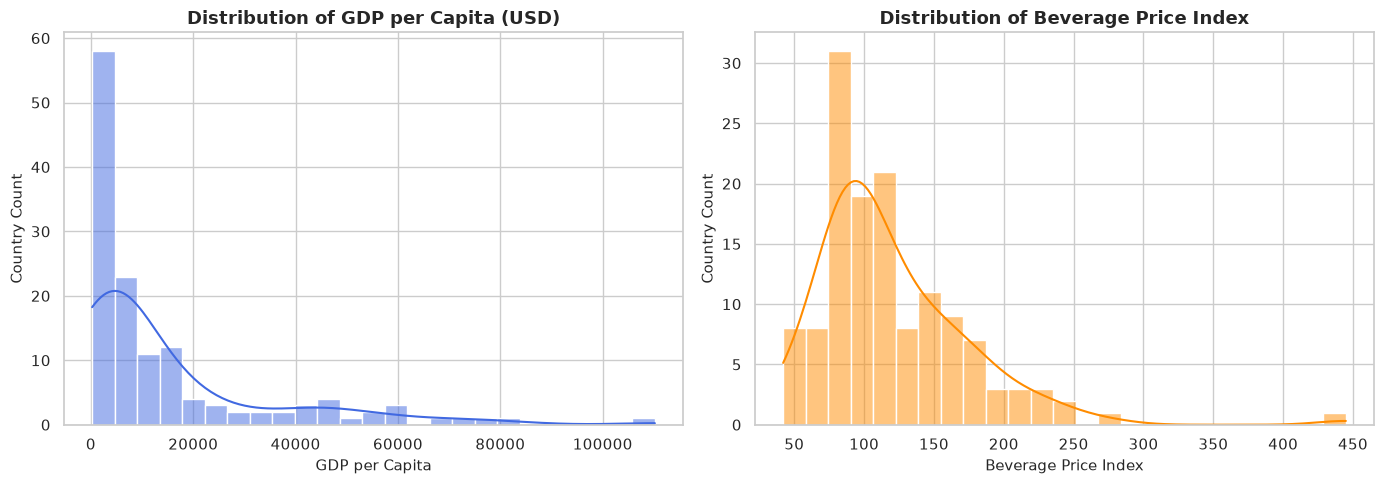

In [3]:
# Visualization 1 & 2: Distribution Grid (GDP per Capita & Beverage Price Index)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# GDP per Capita Distribution
sns.histplot(df['gdppercapita'], kde=True, ax=axes[0], color='royalblue', bins=25)
axes[0].set_title('Distribution of GDP per Capita (USD)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('GDP per Capita', fontsize=11)
axes[0].set_ylabel('Country Count', fontsize=11)

# Beverage Price Index Distribution
sns.histplot(df['beveragepriceindex'], kde=True, ax=axes[1], color='darkorange', bins=25)
axes[1].set_title('Distribution of Beverage Price Index', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Beverage Price Index', fontsize=11)
axes[1].set_ylabel('Country Count', fontsize=11)

plt.tight_layout()
plt.show()

---

### 🔗 3. Correlation Analysis & Heatmap (Visualization 3)
Understanding linear relationships between socioeconomic indicators, pricing, distance, and alcohol consumption.

,alcperpeson,gdppercapita,distancekm,beveragepriceindex,religion
alcperpeson,1.000000,0.367638,0.421192,-0.248926,-0.278527
gdppercapita,0.367638,1.000000,0.525423,0.206725,-0.210212
distancekm,0.421192,0.525423,1.000000,-0.214955,-0.140363
beveragepriceindex,-0.248926,0.206725,-0.214955,1.000000,0.096510
religion,-0.278527,-0.210212,-0.140363,0.096510,1.000000


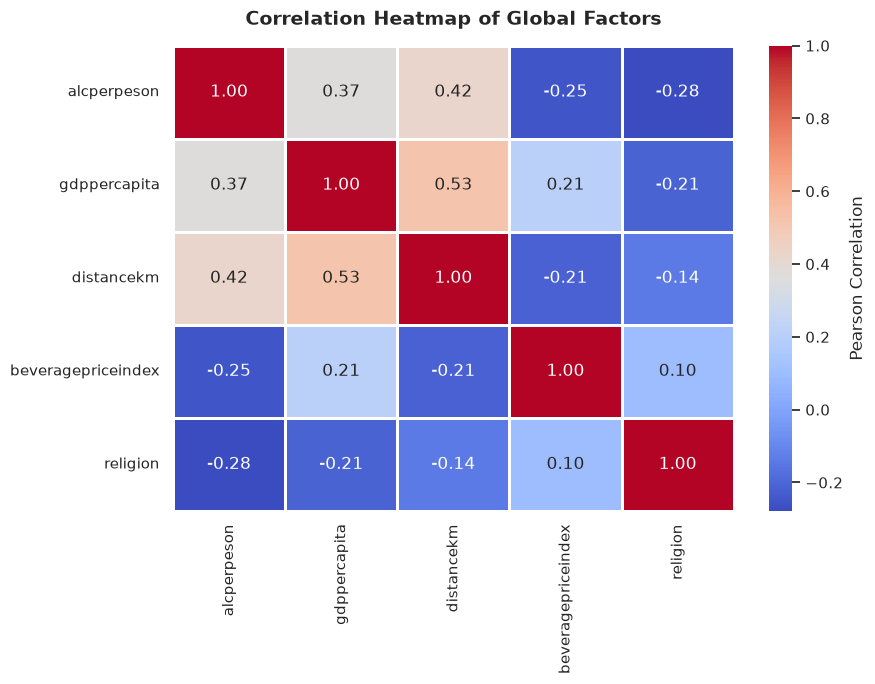

In [4]:
# Compute correlation matrix
numeric_cols = df.drop(columns=['country'])
corr_matrix = numeric_cols.corr()

# Display correlation table
display(corr_matrix)

# Visualization 3: Correlation Heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=1, cbar_kws={'label': 'Pearson Correlation'})
plt.title('Correlation Heatmap of Global Factors', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

---

### 📊 4. Advanced Bivariate Relationships (Visualizations 4 & 5)
* **Visualization 4:** GDP per Capita vs. Alcohol Consumption per Person
* **Visualization 5:** Geographic Distance vs. Alcohol Consumption per Person

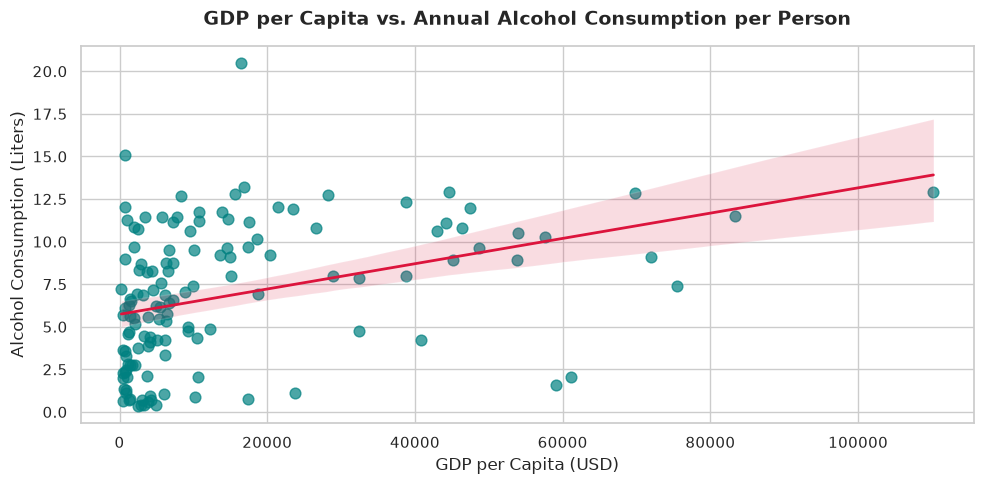

In [5]:
# Visualization 4: GDP per Capita vs Alcohol Consumption with Regression
plt.figure(figsize=(10, 5))
sns.regplot(data=df, x='gdppercapita', y='alcperpeson',
            scatter_kws={'alpha': 0.7, 'color': 'teal', 's': 60},
            line_kws={'color': 'crimson', 'linewidth': 2})
plt.title('GDP per Capita vs. Annual Alcohol Consumption per Person', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('GDP per Capita (USD)', fontsize=12)
plt.ylabel('Alcohol Consumption (Liters)', fontsize=12)
plt.tight_layout()
plt.show()

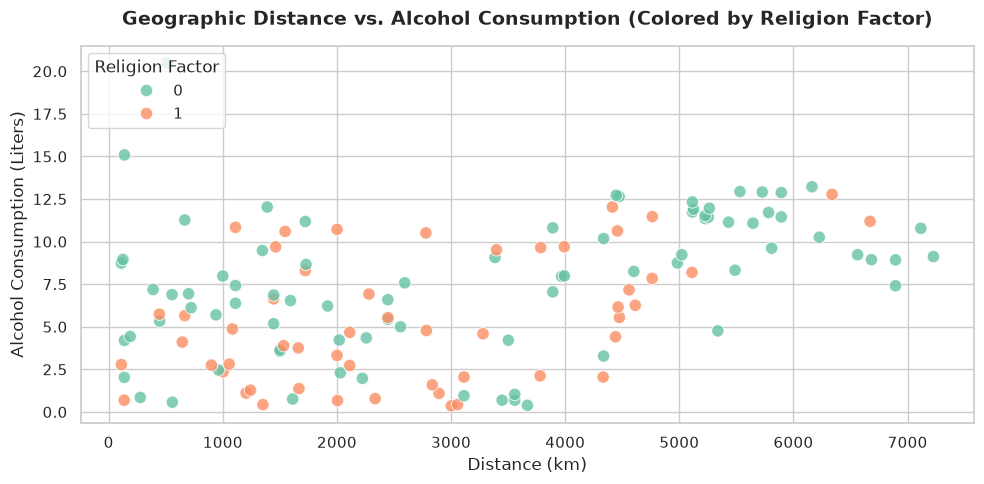

In [6]:
# Visualization 5: Geographic Distance vs. Alcohol Consumption
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='distancekm', y='alcperpeson', hue='religion', palette='Set2', s=80, alpha=0.8)
plt.title('Geographic Distance vs. Alcohol Consumption (Colored by Religion Factor)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Distance (km)', fontsize=12)
plt.ylabel('Alcohol Consumption (Liters)', fontsize=12)
plt.legend(title='Religion Factor', loc='upper left')
plt.tight_layout()
plt.show()

---

### 🏷️ 5. Categorical Grouping & Demographic Breakdown (Visualization 6)
Let's aggregate metrics by the `religion` categorical factor to compare behavioral trends across groups.

--- Aggregated Metrics by Religion Factor ---


,religion,country_count,avg_alc,median_alc,avg_gdp,avg_price_index
0,0,82,7.724390,7.985,18015.246585,116.065488
1,1,53,5.417358,4.780,9394.182264,126.911132


C:\Users\Admin\AppData\Local\Temp\ipykernel_2900\2135311203.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='religion', y='alcperpeson', palette='Pastel1')


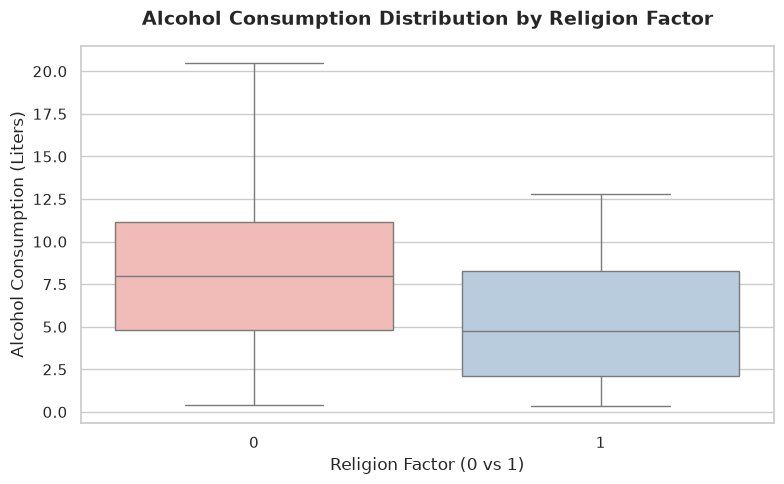

In [7]:
# Groupby analysis by religion factor
religion_grouped = df.groupby('religion').agg(
    country_count=('country', 'count'),
    avg_alc=('alcperpeson', 'mean'),
    median_alc=('alcperpeson', 'median'),
    avg_gdp=('gdppercapita', 'mean'),
    avg_price_index=('beveragepriceindex', 'mean')
).reset_index()

print("--- Aggregated Metrics by Religion Factor ---")
display(religion_grouped)

# Visualization 6: Boxplot comparing Alcohol Consumption across Religion Factors
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='religion', y='alcperpeson', palette='Pastel1')
plt.title('Alcohol Consumption Distribution by Religion Factor', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Religion Factor (0 vs 1)', fontsize=12)
plt.ylabel('Alcohol Consumption (Liters)', fontsize=12)
plt.tight_layout()
plt.show()

---

### 🚨 6. Outlier Detection & Extreme Value Analysis
Identifying statistical outliers in alcohol consumption and economic wealth using Interquartile Range (IQR) analysis.

In [8]:
# IQR method for outlier detection in alcohol consumption
Q1 = df['alcperpeson'].quantile(0.25)
Q3 = df['alcperpeson'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

outliers = df[df['alcperpeson'] > upper_bound]
print(f"--- Outliers in Alcohol Consumption (Threshold > {upper_bound:.2f}L) ---")
display(outliers[['country', 'alcperpeson', 'gdppercapita', 'beveragepriceindex']])

--- Outliers in Alcohol Consumption (Threshold > 20.16L) ---


,country,alcperpeson,gdppercapita,beveragepriceindex
134,Seychelles,20.5,16416.7,223.31


---